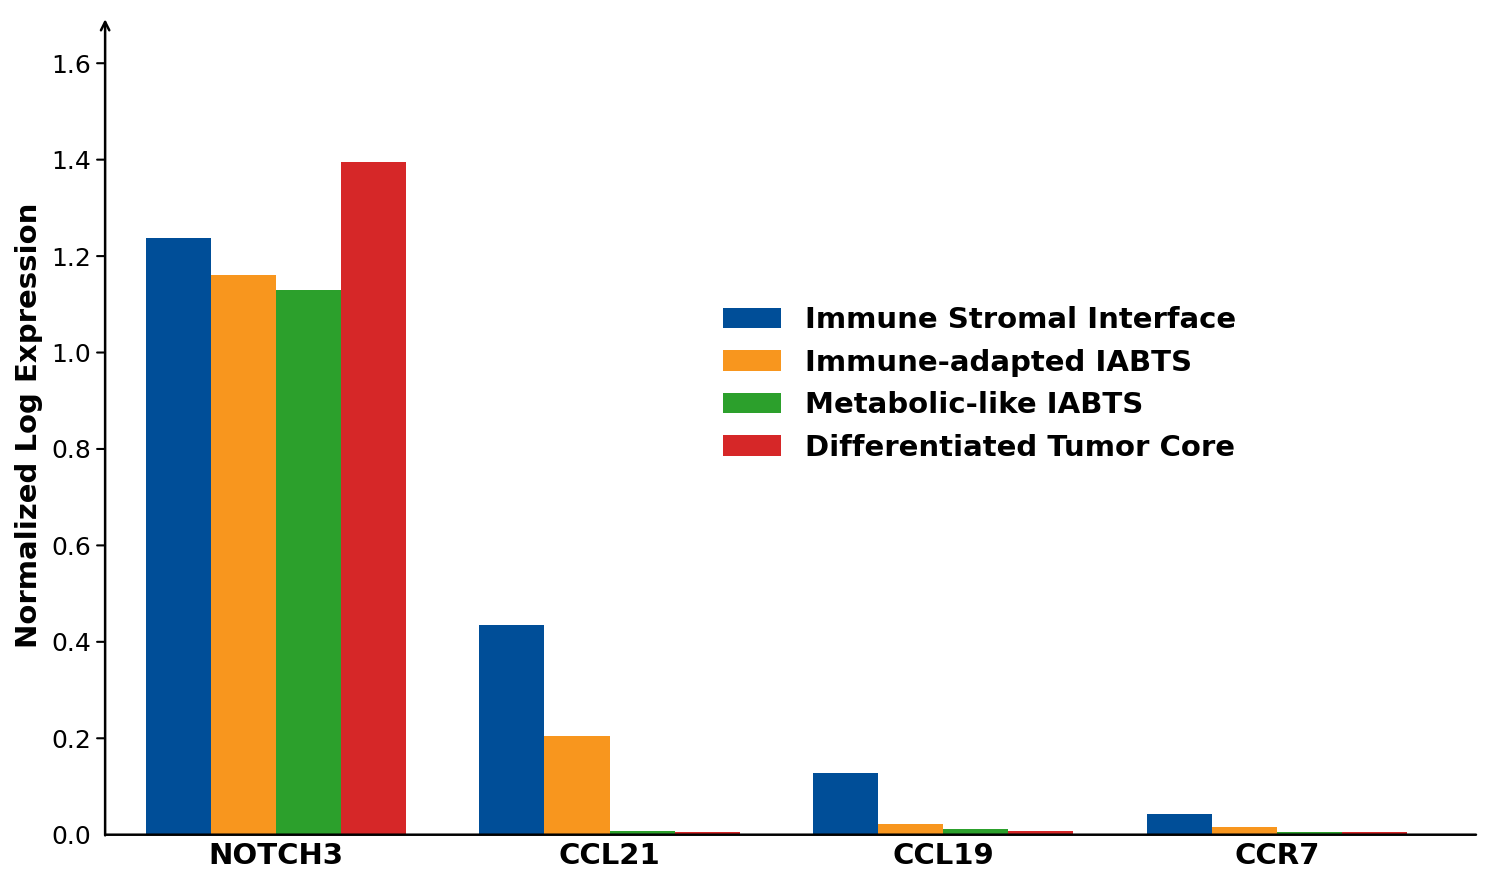

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc

# 0. Load data and preprocess (Normalize by 1e6 and log1p)
adata = sc.read("./h5ad/epi_merged.h5ad")
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)

# 1. Define genes and cell type order
genes = ['NOTCH3', 'CCL21', 'CCL19', 'CCR7']

cell_type_order = [
    'Immune Stromal Interface',
    'Immune-adapted IABTS',
    'Metabolic-like IABTS',
    'Differentiated Tumor Core'
]

# 2. Calculate mean expression for each gene in each cell type
df_means = pd.DataFrame(
    index=genes,
    columns=cell_type_order
)

for gene in genes:
    for cell_type in cell_type_order:
        mask = adata.obs['type'] == cell_type
        df_means.loc[gene, cell_type] = adata[mask, gene].X.mean()

# Ensure all extracted values are numeric floats
df_means = df_means.astype(float)

# 3. Prepare data for plotting
bar_width = 0.08  # Width of a single bar
group_gap = 0.25   # Gap between gene groups
x_pos = np.arange(len(genes)) * (2 * bar_width + group_gap)

# 4. Define specific colors for each cell type based on the original plot
color_map = {
    'Immune Stromal Interface': '#004E98',        # Blue
    'Immune-adapted IABTS': '#F8961E',            # Orange
    'Metabolic-like IABTS': '#2CA02C',            # Green
    'Differentiated Tumor Core': '#D62728'        # Red
}

# 5. Start plotting (width: 10, height: 6)
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# Plot bars for each cell type
for i, cell_type in enumerate(cell_type_order):
    ax.bar(x_pos + i * bar_width, df_means[cell_type], width=bar_width, 
           color=color_map[cell_type], align='center', label=cell_type)

# 6. Style adjustments
# Center X-axis labels in the middle of each gene group
ax.set_xticks(x_pos + (len(cell_type_order) - 1) * bar_width / 2)
ax.set_xticklabels(genes, fontsize=14, fontweight='bold')

# Y-axis ticks and labels
ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6])
ax.set_yticklabels(['0.0', '0.2', '0.4', '0.6', '0.8', '1.0', '1.2', '1.4', '1.6'], fontsize=12)
ax.set_ylabel('Normalized Log Expression', fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.7)

# Legend (placed on the right, bold font)
legend = ax.legend(loc='center right', bbox_to_anchor=(0.85, 0.55), fontsize=14, frameon=False)
for text in legend.get_texts():
    text.set_fontweight('bold')

# Hide default spines
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='x', length=0)

# Manually draw bottom X-axis line (no arrow on the left)
ax.annotate(
    '', xy=(-0.095, 0), xytext=(1.6, 0.),
    xycoords='data',
    arrowprops=dict(arrowstyle='-', lw=1.2, color='black')
)

# Manually draw left Y-axis line with top arrow
ax.annotate(
    '', xy=(-0.09, 1.7), xytext=(-0.09, -0.01),
    xycoords='data',
    arrowprops=dict(arrowstyle='->', lw=1.2, color='black')
)

# Manually draw Y-axis tick lines (extending leftward)
yticks_pos = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
for y in yticks_pos:
    ax.annotate(
        '', xy=(-0.105, y), xytext=(-0.085, y),
        xycoords='data',
        arrowprops=dict(arrowstyle='-', lw=1.0, color='black')
    )
ax.tick_params(axis='y', direction='out', length=0, pad=-4)

plt.tight_layout()
plt.show()